# 02: Improved Method: Fixing the Three Weaknesses Found in the Baseline

**Where we are:** notebook 01 reproduced the original method with Qwen 2.5 (7B) and scored **ACC 0.399, NMI 0.558, ARI 0.320** on massive_scenario. The results showed three clear causes:

| Cause found in baseline | Evidence | Fix in this notebook |
|---|---|---|
| 1. Weak merge: 71 labels for 18 true topics | `alarm` / `alarms_reminders` / `alarms_reminders_time` stayed separate | **Fix B: embedding-based merge** |
| 2. Catch-all labels absorb texts | `miscellaneous` (106 texts), `information_request` (127), `other` | **Fix A: remove catch-all labels** |
| 3. 175 texts lost as "Unsuccessful" | Qwen answered with a label not exactly in the list | **Fix C: rescue answers by meaning** |

**Fair comparison:** we reuse the **same 76 labels** that the LLM generated in notebook 01, before the merge. Only the merge and classification steps change, so any difference in score comes from our fixes and not from a different label generation run.

**Why embeddings for the fixes?** A small embedding model turns each label into a vector, so labels with similar meaning end up close together. It's cheap (no LLM calls), fast and deterministic, which is exactly what a 7B LLM struggled with.

**Steps:** 0 Setup → 1 Embedding model → Fix A → Fix B → 2 Classify → Fix C → 3 Evaluate → 4 Compare → Findings

## 0. Setup
Same setup as notebook 01. **To test another model, change `MODEL` here and in notebook 01, and run 01 first.** Each model has its own files and rows, so nothing is overwritten. We also load the baseline's generated labels and its score, for comparison at the end.

**First time only:** install the embedding library in the VS Code terminal:
```
python -m pip install sentence-transformers ipywidgets
```

In [6]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json, time, math, importlib
import numpy as np
import pandas as pd
from types import SimpleNamespace

#DATA = "massive_scenario"
#MODEL = "qwen3:8b"
DATA = "massive_intent"
MODEL = "qwen2.5:7b"
SIZE = "small"
OUT = "./generated_labels" if MODEL == "qwen2.5:7b" else f"./generated_labels/{MODEL.replace(':', '_')}"
CHOSEN = "./generated_labels/chosen_labels.json"
os.makedirs("./results", exist_ok=True)

def out_file(name):
    return f"{OUT}/{DATA}_{SIZE}_{name}.json"

with open(out_file("llm_generated_labels_before_merge"), encoding="utf-8") as f:
    before = json.load(f)               # the same 76 labels the baseline started from
with open(CHOSEN, encoding="utf-8") as f:
    seed_labels = json.load(f)[DATA]    # the 20% example labels given to the LLM (part of the method's input)

import evaluate as ev
gold = ev.load_data("./dataset/", DATA, SIZE == "large")
texts = [g["input"] for g in gold]
n_texts = len(texts)

results = pd.read_csv("./results/results.csv")
base_rows = results[(results.method == "baseline") & (results.dataset == DATA) & (results.model == MODEL)]
assert len(base_rows), f"No baseline for {MODEL} yet: run 01_baseline.ipynb with this model first."
baseline = base_rows.iloc[-1]
print(f"{n_texts} texts | {len(before)} generated labels | seed labels: {seed_labels}")
print(f"Baseline: ACC {baseline.ACC}, NMI {baseline.NMI}, ARI {baseline.ARI}, {baseline.predicted_clusters} clusters")

2974 texts | 156 generated labels | seed labels: ['music query', 'play music', 'iot hue lightoff', 'iot hue lightup', 'transport ticket', 'email sendemail', 'news query', 'social post', 'cooking recipe', 'qa stock', 'email querycontact']
Baseline: ACC 0.3312, NMI 0.5136, ARI 0.0743, 92 clusters


## 1. Load the embedding model
**Why `all-MiniLM-L6-v2`:** it's small (~80 MB), runs fast even on a CPU, and works well for short phrases like label names. We use it **only** to compare labels and answers, never to cluster the texts directly, so the LLM still does the clustering, as in the original method.

The first run downloads the model once.

In [7]:
from sentence_transformers import SentenceTransformer
embedder = SentenceTransformer("all-MiniLM-L6-v2")

def embed(items):
    # Labels like "play_music" become "play music" so the model reads them as words
    return embedder.encode([str(x).replace("_", " ") for x in items], normalize_embeddings=True)

print("Embedding model ready.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model ready.


## Fix A: Remove catch-all labels
**Why:** in the baseline chart, vague labels like `miscellaneous`, `other` and `information_request` collected hundreds of texts that belong to real topics (weather, music, alarms...). Labels that describe *no* topic can't form a meaningful cluster.

**How:** a short, fixed list of generic words. Any label made only of these words is removed. The list is written by hand and **not tuned on the true labels**, so it doesn't leak the answers.

In [8]:
GENERIC_WORDS = {"other", "others", "misc", "miscellaneous", "general", "unknown", "request", "requests",
                 "query", "queries", "question", "info", "information", "informational", "action",
                 "service", "search", "task", "personal"}

def is_catch_all(label):
    words = label.lower().replace("-", "_").split("_")
    return all(w in GENERIC_WORDS for w in words)

removed = [l for l in before if is_catch_all(l) and l not in seed_labels]   # never remove a seed label
labels_A = [l for l in before if l not in removed]
print(f"Removed {len(removed)} catch-all labels: {removed}")
print(f"{len(before)} → {len(labels_A)} labels")

Removed 0 catch-all labels: []
156 → 156 labels


## Fix B: Embedding-based merge
**Why:** the baseline's single-call LLM merge only reduced 76 → 71 labels. Embeddings can group labels with the same meaning (`alarm` and `alarms_reminders`, `music` and `play_music`) reliably and without any LLM call.

**How:** agglomerative clustering on the label embeddings with cosine distance. Labels closer than a **distance threshold** are grouped together. Each group keeps one representative name:
- a **seed label** if the group contains one (these are the example labels the method already gives the LLM);
- otherwise, the label most similar to the rest of its group.

### Choosing the threshold (without looking at the true labels)
The cell below shows how many labels each threshold produces. A small threshold merges almost nothing, a large one merges unrelated topics. We pick a value where obvious duplicates are merged but distinct topics stay apart, by **reading the groups**, not by checking the score. Picking by score would be cheating, since in real use there are no true labels.

In [9]:
from sklearn.cluster import AgglomerativeClustering

E_A = embed(labels_A)

def group_labels(labels, E, threshold):
    if len(labels) < 2:
        return [list(labels)]
    model = AgglomerativeClustering(n_clusters=None, distance_threshold=threshold, metric="cosine", linkage="average")
    ids = model.fit_predict(E)
    groups = {}
    for lab, g in zip(labels, ids):
        groups.setdefault(g, []).append(lab)
    return list(groups.values())

sweep = [(t, len(group_labels(labels_A, E_A, t))) for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]]
pd.DataFrame(sweep, columns=["distance threshold", "labels after merge"])

,distance threshold,labels after merge
0,0.2,115
1,0.3,88
2,0.4,61
3,0.5,35
4,0.6,25
5,0.7,16


### Apply the merge and inspect the groups
Start with `THRESHOLD = 0.5`, then read the groups printed below:
- If clear duplicates are still separate, **increase** it a little (e.g. 0.55).
- If unrelated topics are grouped together (e.g. `weather` with `music`), **decrease** it.

Write down the value you choose; it goes in the paper's experimental setup.

In [48]:
THRESHOLD = 0.4

def representative(group, labels, E):
    seeds = [l for l in group if l in seed_labels]
    if seeds:
        return seeds[0]
    idx = [labels.index(l) for l in group]
    sims = E[idx] @ E[idx].T
    return group[int(np.argmax(sims.mean(axis=1)))]

groups = group_labels(labels_A, E_A, THRESHOLD)
labels_B = [representative(g, labels_A, E_A) for g in groups]

for g, rep in sorted(zip(groups, labels_B), key=lambda x: -len(x[0])):
    if len(g) > 1:
        print(f"{rep:25s} ← {sorted(g)}")
print(f"\n{len(labels_A)} → {len(labels_B)} labels after embedding merge (threshold {THRESHOLD})")
print(sorted(labels_B))

with open(out_file(f"improved_labels_t{THRESHOLD}"), "w", encoding="utf-8") as f:
    json.dump(labels_B, f, indent=2, ensure_ascii=False)

qa                        ← ['qa', 'qa definition', 'qa education', 'qa entertainment', 'qa general', 'qa health', 'qa organization', 'qa personal', 'qa relationship', 'qa_biology', 'qa_book', 'qa_definition', 'qa_entertainment', 'qa_event', 'qa_events', 'qa_general', 'qa_list', 'qa_meeting', 'qa_movie', 'qa_music', 'qa_news', 'qa_person', 'qa_personality', 'qa_philosophy', 'qa_politics', 'qa_word_definition']
iot hue lightoff          ← ['iot hue lightcontrol', 'iot hue lightdown', 'iot hue lightoff', 'iot hue lightquery', 'iot hue lightup', 'iot_hue_lightcontrol', 'iot_hue_lightoff', 'iot_hue_lighton', 'iot_hue_lightup']
qa time                   ← ['qa date', 'qa schedule', 'qa time', 'qa_date', 'qa_schedule', 'qa_time', 'qa_time_zone']
set reminder              ← ['qa_reminder', 'reminder', 'reminder query', 'reminder request', 'reminder setting', 'reminder_set', 'set reminder']
calendar                  ← ['calendar', 'calendar event', 'calendar management', 'calendar query', 'cal

### Threshold check: Massive-I (Qwen 2.5 7B)
- **0.5 (35 labels, true 59): too aggressive for an intent dataset.** All ~50 `qa ...` labels merged into one, the light actions (`lightoff`, `lightup`, `lightdown`) merged, and `play music` merged with `music query`.
- **0.4 (61 labels):** most intents stay apart: the qa labels split by topic (`qa time`, `qa_location`, `qa stock`, `qa_currency`, `math`), `play music` vs `music query`, and `email sendemail` vs `email_query` vs `email querycontact`.
- **Remaining errors at 0.4:** labels that differ only in the action word are still merged (`lightoff`/`lightup`/`lightdown`, `alarm setting` + `alarms query`, `reminder setting` + `reminder query`). The embedding model sees them as near-identical.

**Decision:** we use **0.4** for Massive-I (same rule: the largest threshold that keeps distinct clusters apart). Intent datasets need a lower threshold than topic datasets (Massive-D: 0.5), because their clusters often differ by a single action word.

### Threshold check for Qwen3 8B
- Fix A removed 13 catch-all labels (350 → 337).
- **0.5 (149 labels):** merges correct, but far too many labels remain (Qwen3 generated 4.6× more labels than Qwen 2.5).
- **0.6 (96 labels):** merges still keep topics apart: `music` vs `audio`, `news` vs `politics`, and `weather`, `email`, `takeout` all stay separate. A few small questionable merges: `calendar` → `birthday`, `job`/`tasks`/`work` → `craft`, `payment` → `delivery`, `computer`/`phone` → `social media`.

**Decision:** we use **0.6** for Qwen3. It's the same rule as for Qwen 2.5 (the largest threshold that keeps distinct topics apart, chosen by reading the groups), but Qwen3's label list is much denser, so topics only start to mix at a higher threshold.

### Threshold check: what the groups looked like (Qwen 2.5 7B run)
- **0.5 (36 labels):** merges were mostly correct (all alarm labels, all date/time labels, music/play_music). One error: `social_media` merged into `media`.
- **0.55 (26 labels):** wrong merges start to appear: `music` + `radio` + `audio` (three different true topics), `politics` + `sports`, `planning` + `policy`.
- **0.6 (20 labels):** clearly too aggressive: `news` + `politics` + `sports` + `social_media` + `media` became one cluster, and `crime` + `finance` + `shopping` + `credit` another.

**Decision:** we keep **0.5**, the largest threshold that keeps distinct topics apart. 0.55 and 0.6 are run only as a sensitivity analysis. The threshold is chosen by reading the groups, not by the score, because real use has no true labels.

*For other models, check the printed groups again before classifying: the label names differ per model.*

## 2. Classify every text with the improved label list
**Same as the baseline:** one LLM call per text, the same prompt and the same model. Only the label list is different (the output of Fix A + Fix B).

**Two changes in how we run it (not in the method):**
- **Raw answers are saved** for every text, so Fix C can be tested afterwards *without* calling the LLM again.
- **Progress is saved line by line.** If the run stops (PC sleep, crash), running the cell again continues where it stopped instead of starting over.

This takes about as long as the baseline (~25–30 min).

In [49]:
import given_label_classification as glc
from tqdm.auto import tqdm
importlib.reload(glc)
glc.MODEL = MODEL
glc.BASE_URL = "http://localhost:11434/v1"
client = glc.ini_client(SimpleNamespace(base_url="http://localhost:11434/v1", api_key="ollama"))

def classify_all(label_list, tag):
    raw_path = f"{OUT}/{DATA}_{SIZE}_{tag}_raw.jsonl"
    done = {}
    if os.path.exists(raw_path):
        with open(raw_path, encoding="utf-8") as f:
            for line in f:
                r = json.loads(line); done[r["i"]] = r["raw"]
    t0 = time.time()
    with open(raw_path, "a", encoding="utf-8") as f:
        for i, text in enumerate(tqdm(texts, desc=tag)):
            if i in done:
                continue
            raw = glc.chat(glc.prompt_construct(label_list, text), client)
            done[i] = raw
            f.write(json.dumps({"i": i, "raw": raw}, ensure_ascii=False) + "\n"); f.flush()
    minutes = (time.time() - t0) / 60
    return [done[i] for i in range(len(texts))], minutes

TAG = f"improved_t{THRESHOLD}"
raw_answers, time_classify = classify_all(labels_B, TAG)
print(f"Done. Time this session: {time_classify:.1f} min")

improved_t0.4:   0%|          | 0/2974 [00:00<?, ?it/s]

Done. Time this session: 0.0 min


## Fix C: Rescue failed answers by meaning
**Why:** in the baseline, 175 texts (5.9%) went to "Unsuccessful" because Qwen's answer was not *exactly* one of the labels (e.g. it answered `alarm_setting` when the list had `alarm`). The model understood the text but the strict string match threw the answer away.

**How:** if the answer matches a label exactly, keep it (same as the original). If it doesn't, embed the answer and assign the **closest label by meaning**. This needs **no extra LLM calls**, since it reuses the saved raw answers.

We compute both versions, so we can measure Fix C separately:
- **without rescue:** the original strict matching;
- **with rescue:** strict matching plus the embedding fallback.

In [50]:
def answer_text(raw):
    try:
        obj = glc.parse_json(raw)
        vals = [v for v in obj.values() if isinstance(v, str)]
        return vals[0] if vals else str(raw)
    except Exception:
        return str(raw or "")

strict = [glc.answer_process(r, labels_B) if r else "Unsuccessful" for r in raw_answers]
failed_idx = [i for i, p in enumerate(strict) if p == "Unsuccessful"]

rescued = list(strict)
if failed_idx:
    E_B = embed(labels_B)
    E_ans = embed([answer_text(raw_answers[i]) for i in failed_idx])
    nearest = (E_ans @ E_B.T).argmax(axis=1)
    for i, j in zip(failed_idx, nearest):
        rescued[i] = labels_B[j]

print(f"Unsuccessful with strict matching: {len(failed_idx)}")
for i in failed_idx[:10]:
    print(f"  answer: {answer_text(raw_answers[i])!r:35} → rescued as: {rescued[i]}")

Unsuccessful with strict matching: 433
  answer: 'alarm_setting'                     → rescued as: alarm setting
  answer: 'cleaning_task'                     → rescued as: cleaning task
  answer: 'cleaning_task'                     → rescued as: cleaning task
  answer: 'alarm_setting'                     → rescued as: alarm setting
  answer: 'alarm_setting'                     → rescued as: alarm setting
  answer: 'alarm_setting'                     → rescued as: alarm setting
  answer: 'qa_time'                           → rescued as: qa time
  answer: 'qa_time'                           → rescued as: qa time
  answer: 'food_order'                        → rescued as: food order
  answer: 'delivery_query'                    → rescued as: transport_query


## 3. Evaluate
Same metrics as the baseline (ACC, NMI, ARI). As in the original `evaluate.py`, "Unsuccessful" counts as its own cluster, so the "without rescue" result is directly comparable to the baseline.

In [51]:
y_true_raw = ev.get_labels(gold)

def score(preds):
    y_true, k_true = ev.convert_label_to_ids(y_true_raw)
    y_pred, k_pred = ev.convert_label_to_ids(preds)
    s = {k: round(float(v), 4) for k, v in ev.clustering_score(y_true, y_pred).items()}
    return s, k_pred

rows = []
llm_calls = math.ceil(n_texts / 15) + n_texts   # label generation (reused) + classification; no LLM merge call
for name, preds in [("A+B (merge)", strict), ("A+B+C (merge + rescue)", rescued)]:
    s, k = score(preds)
    rows.append({"method": name, "dataset": DATA, "model": MODEL, "n_texts": n_texts,
                 "true_clusters": len(set(y_true_raw)), "predicted_clusters": k, **s,
                 "unsuccessful": preds.count("Unsuccessful"), "llm_calls": llm_calls,
                 "time_min": round(time_classify, 1), "threshold": THRESHOLD,
                 "date": time.strftime("%Y-%m-%d %H:%M")})
new = pd.DataFrame(rows)
new

Length of labels: 2974
Number of Clusters: 59
Length of labels: 2974
Number of Clusters: 51
Length of labels: 2974
Number of Clusters: 59
Length of labels: 2974
Number of Clusters: 59


,method,dataset,model,n_texts,true_clusters,predicted_clusters,ACC,ARI,NMI,unsuccessful,llm_calls,time_min,threshold,date
0,A+B (merge),massive_intent,qwen2.5:7b,2974,59,51,0.4206,0.2803,0.6116,433,3173,0.0,0.4,2026-11-08 21:20
1,A+B+C (merge + rescue),massive_intent,qwen2.5:7b,2974,59,59,0.4580,0.3696,0.6636,0,3173,0.0,0.4,2026-11-08 21:20


## 4. Compare with the baseline and save
The new rows are added to `results/results.csv`. Rerunning this cell replaces the rows of the same method and threshold, so there are no duplicates.

In [52]:
results = pd.read_csv("./results/results.csv")
if "threshold" not in results.columns:
    results["threshold"] = np.nan
keep = ~(results.method.isin(new.method) & (results.dataset == DATA) & (results.model == MODEL) & (results.threshold == THRESHOLD))
results = pd.concat([results[keep], new], ignore_index=True)
results.to_csv("./results/results.csv", index=False)

cols = ["method", "threshold", "predicted_clusters", "ACC", "NMI", "ARI", "unsuccessful", "llm_calls", "time_min"]
results[(results.dataset == DATA) & (results.model == MODEL)][cols]

,method,threshold,predicted_clusters,ACC,NMI,ARI,unsuccessful,llm_calls,time_min
22,baseline,NaN,92,0.3312,0.5136,0.0743,1131,3174,13.2
23,A+B+D (merge + discovery),0.4,60,0.4627,0.6667,0.3723,0,3173,10.6
24,A+B (merge),0.3,68,0.3406,0.5341,0.0917,1079,3173,10.8
25,A+B+C (merge + rescue),0.3,88,0.4556,0.6651,0.3615,0,3173,10.8
26,A+B+D (merge + discovery),0.3,88,0.4556,0.6651,0.3615,0,3173,10.8
27,A+B (merge),0.5,29,0.3194,0.4887,0.1145,1118,3173,10.4
28,A+B+C (merge + rescue),0.5,34,0.4778,0.6377,0.3616,0,3173,10.4
29,A+B+D (merge + discovery),0.5,37,0.4842,0.6457,0.3723,0,3173,10.4
30,A+B (merge),0.4,51,0.4206,0.6116,0.2803,433,3173,0.0
31,A+B+C (merge + rescue),0.4,59,0.4580,0.6636,0.3696,0,3173,0.0


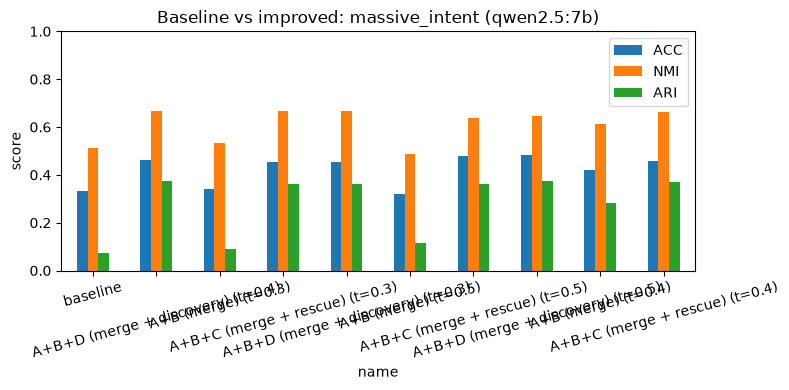

In [53]:
import matplotlib.pyplot as plt
view = results[(results.dataset == DATA) & (results.model == MODEL)].copy()
view["name"] = view.apply(lambda r: r.method if pd.isna(r.threshold) else f"{r.method} (t={r.threshold})", axis=1)
view.set_index("name")[["ACC", "NMI", "ARI"]].plot.bar(figsize=(8, 4), rot=15)
plt.title(f"Baseline vs improved: {DATA} ({MODEL})"); plt.ylim(0, 1); plt.ylabel("score")
plt.tight_layout(); plt.show()

### Predicted cluster sizes after the fixes
Compare this with the baseline chart in notebook 01: there should be far fewer, larger clusters and no catch-all groups.

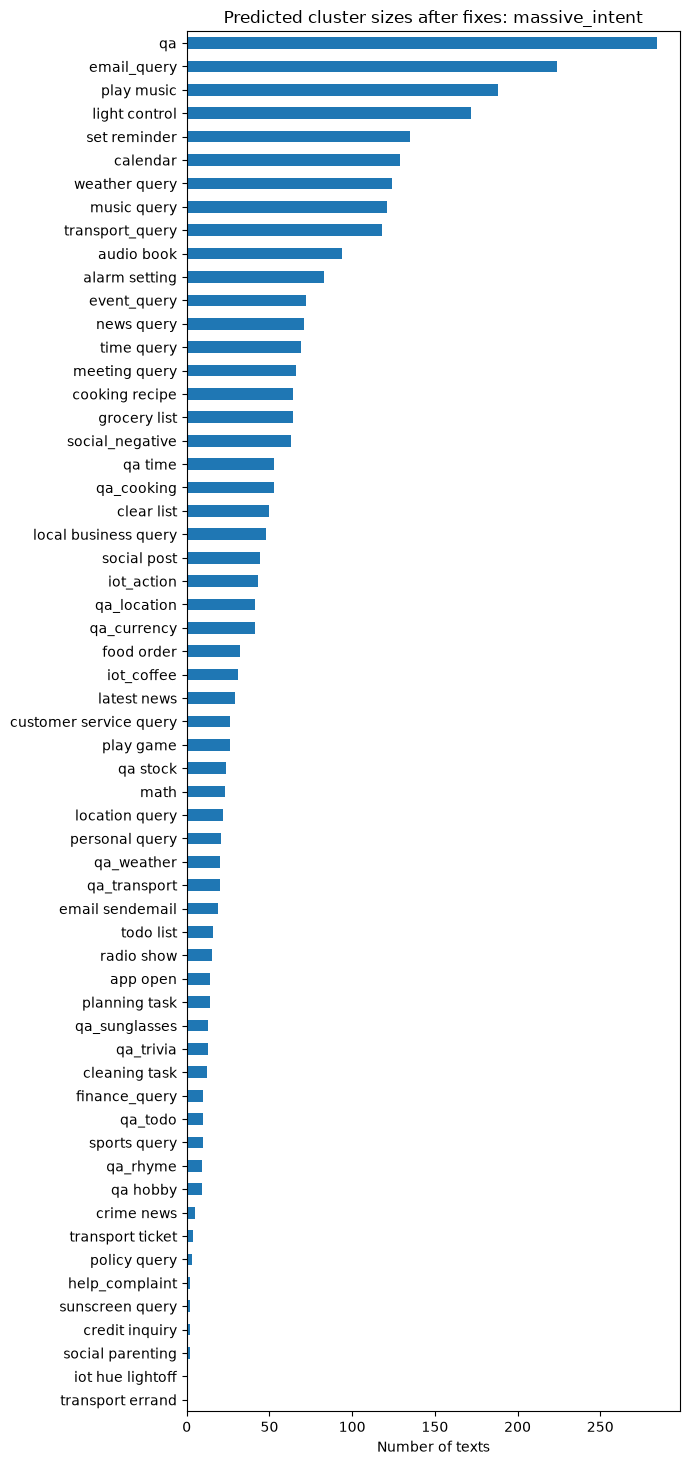

In [54]:
pd.Series(rescued).value_counts().sort_values().plot.barh(figsize=(7, max(3, len(set(rescued)) * 0.25)))
plt.title(f"Predicted cluster sizes after fixes: {DATA}")
plt.xlabel("Number of texts"); plt.tight_layout(); plt.show()

## Fix D: Discover missing clusters from failed answers
**Why:** Fix C showed that most failed answers were **not** spelling variants of existing labels but **new topics** the label list was missing: `delivery`, `food`, `restaurant` (true topic: takeaway) and `joke`, `knock_knock` (true topic: general). Forcing them into the nearest label put them in the wrong cluster (`joke` → `complaints`).

**Idea:** a failed answer is a signal, not just an error.
1. If the answer is **close** in meaning to an existing label, rescue it as in Fix C.
2. If it's **far** from every label, it probably names a missing topic. We collect these answers, group similar ones with the same embedding merge as Fix B, and turn each large enough group into a **new cluster**.

This reuses the saved answers, so it costs **no extra LLM calls**.

### D1. How close is each failed answer to the existing labels?
We print every distinct failed answer with its closest label and the cosine similarity (1 = same meaning). This shows where to put the cut-off between "variant of an existing label" and "new topic", again by **reading the answers, not by checking the score**.

In [55]:
E_B = embed(labels_B)
fail_answers = [answer_text(raw_answers[i]).strip().lower() for i in failed_idx]
uniq = sorted(set(fail_answers))
E_u = embed(uniq)
sim_u = E_u @ E_B.T
best_sim = sim_u.max(axis=1)
best_lab = [labels_B[j] for j in sim_u.argmax(axis=1)]
counts = pd.Series(fail_answers).value_counts()

d1 = pd.DataFrame({"answer": uniq, "texts": [counts[a] for a in uniq],
                   "closest label": best_lab, "similarity": best_sim.round(2)})
d1 = d1.sort_values("similarity", ascending=False).reset_index(drop=True)
print(f"{len(failed_idx)} failed texts, {len(uniq)} distinct answers")
pd.set_option("display.max_rows", 200)
d1

433 failed texts, 46 distinct answers


,answer,texts,closest label,similarity
0,alarm_setting,83,alarm setting,1.00
1,app_open,11,app open,1.00
2,cleaning_task,3,cleaning task,1.00
3,clear_list,14,clear list,1.00
4,latest_news,3,latest news,1.00
5,credit_inquiry,1,credit inquiry,1.00
6,location_query,9,location query,1.00
7,email_sendemail,18,email sendemail,1.00
8,food_order,3,food order,1.00
9,play_music,20,play music,1.00


### D2. Rescue close answers, turn far answers into new clusters
Settings, chosen by reading the D1 table:
- `RESCUE_SIM`: answers at or above this similarity are rescued into their closest label. Below it, they are treated as a new topic. We use **0.55** (chosen from the Qwen 2.5 D1 table; kept the same for all models for a fair comparison), and check in D1 that answers above it really are variants (e.g. `alarm_setting` → alarm) and those below are new topics (e.g. `delivery`).
- `NEW_T`: distance threshold for grouping the new-topic answers (same method as Fix B; we keep **0.5** for consistency).
- `MIN_SIZE`: a new cluster needs at least this many texts. Smaller groups are too weak to be a topic and go to their closest existing label instead. Start with **5**.

In [56]:
RESCUE_SIM = 0.55
NEW_T = 0.5
MIN_SIZE = 5

sim_of = dict(zip(uniq, best_sim)); near_of = dict(zip(uniq, best_lab))
far = [a for a in uniq if sim_of[a] < RESCUE_SIM]

# Group the far answers by meaning; name each group after its most frequent answer
new_name_of = {}
if far:
    E_far = embed(far)
    for g in group_labels(far, E_far, NEW_T):
        name = max(g, key=lambda a: counts[a])
        size = sum(counts[a] for a in g)
        for a in g:
            new_name_of[a] = ("NEW:" + name) if size >= MIN_SIZE else None

discovered = list(rescued)          # start from Fix C, then overwrite the failed texts
n_rescue = n_new = 0
for i, a in zip(failed_idx, fail_answers):
    if sim_of[a] < RESCUE_SIM and new_name_of.get(a):
        discovered[i] = new_name_of[a]; n_new += 1
    else:
        discovered[i] = near_of[a]; n_rescue += 1

new_clusters = pd.Series([p for p in discovered if p.startswith("NEW:")]).value_counts()
print(f"Rescued into existing labels: {n_rescue} texts | put into new clusters: {n_new} texts")
print(f"New clusters discovered: {len(new_clusters)}\n")
for name in new_clusters.index:
    members = sorted({a for a in far if new_name_of.get(a) == name})
    print(f"{name:25s} {new_clusters[name]:4d} texts ← {members}")

Rescued into existing labels: 413 texts | put into new clusters: 20 texts
New clusters discovered: 1

NEW:movie query             20 texts ← ['movie query', 'movie_query', 'tv_show_query']


### D3. Evaluate Fix D and save
Same metrics and same table as before. The new row is **A+B+D (merge + discovery)**: it replaces the plain rescue of Fix C with rescue + discovery.

In [57]:
s, k = score(discovered)
row_d = {"method": "A+B+D (merge + discovery)", "dataset": DATA, "model": MODEL, "n_texts": n_texts,
         "true_clusters": len(set(y_true_raw)), "predicted_clusters": k, **s, "unsuccessful": 0,
         "llm_calls": llm_calls, "time_min": round(time_classify, 1), "threshold": THRESHOLD,
         "rescue_sim": RESCUE_SIM, "min_size": MIN_SIZE, "date": time.strftime("%Y-%m-%d %H:%M")}

results = pd.read_csv("./results/results.csv")
for col in ["threshold", "rescue_sim", "min_size"]:
    if col not in results.columns:
        results[col] = np.nan
keep = ~((results.method == row_d["method"]) & (results.dataset == DATA) & (results.model == MODEL) & (results.threshold == THRESHOLD)
         & (results.rescue_sim == RESCUE_SIM) & (results.min_size == MIN_SIZE))
results = pd.concat([results[keep], pd.DataFrame([row_d])], ignore_index=True)
results.to_csv("./results/results.csv", index=False)

cols = ["method", "threshold", "rescue_sim", "min_size", "predicted_clusters", "ACC", "NMI", "ARI", "llm_calls"]
results[(results.dataset == DATA) & (results.model == MODEL)][cols]

Length of labels: 2974
Number of Clusters: 59
Length of labels: 2974
Number of Clusters: 60


,method,threshold,rescue_sim,min_size,predicted_clusters,ACC,NMI,ARI,llm_calls
22,baseline,NaN,NaN,NaN,92,0.3312,0.5136,0.0743,3174
23,A+B (merge),0.3,NaN,NaN,68,0.3406,0.5341,0.0917,3173
24,A+B+C (merge + rescue),0.3,NaN,NaN,88,0.4556,0.6651,0.3615,3173
25,A+B+D (merge + discovery),0.3,0.55,5.0,88,0.4556,0.6651,0.3615,3173
26,A+B (merge),0.5,NaN,NaN,29,0.3194,0.4887,0.1145,3173
27,A+B+C (merge + rescue),0.5,NaN,NaN,34,0.4778,0.6377,0.3616,3173
28,A+B+D (merge + discovery),0.5,0.55,5.0,37,0.4842,0.6457,0.3723,3173
29,A+B (merge),0.4,NaN,NaN,51,0.4206,0.6116,0.2803,3173
30,A+B+C (merge + rescue),0.4,NaN,NaN,59,0.4580,0.6636,0.3696,3173
31,A+B+D (merge + discovery),0.4,0.55,5.0,60,0.4627,0.6667,0.3723,3173


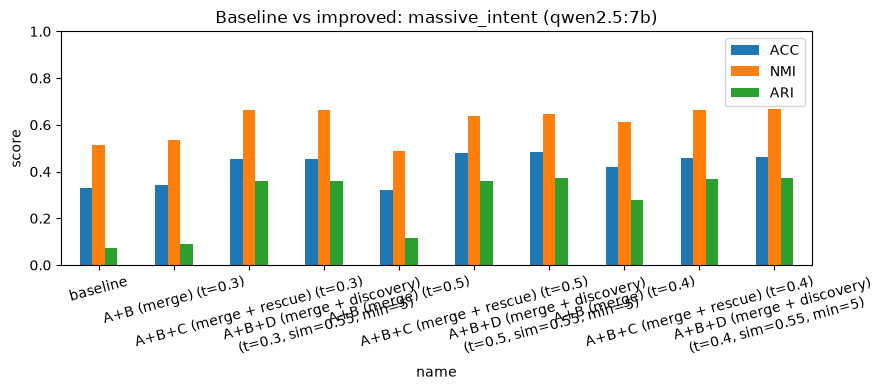

In [58]:
view = results[(results.dataset == DATA) & (results.model == MODEL)].copy()
def nice(r):
    if r.method == "A+B+D (merge + discovery)":
        return f"{r.method}\n(t={r.threshold}, sim={r.rescue_sim}, min={int(r.min_size)})"
    return r.method if pd.isna(r.threshold) else f"{r.method} (t={r.threshold})"
view["name"] = view.apply(nice, axis=1)
view.set_index("name")[["ACC", "NMI", "ARI"]].plot.bar(figsize=(9, 4), rot=15)
plt.title(f"Baseline vs improved: {DATA} ({MODEL})"); plt.ylim(0, 1); plt.ylabel("score")
plt.tight_layout(); plt.show()

### Findings for Fix D (Qwen 2.5 7B run, RESCUE_SIM = 0.55, MIN_SIZE = 5)
1. **New clusters:** 5 clusters were discovered from 72 failed texts: `recipe` (32: cooking, food, recipe, restaurant), `movie` (21: movie, tv_show), `calendar` (7), `math` (7: math, statistics) and `delivery` (5: delivery, order). Most match real topics missing from the label list (cooking, takeaway, qa). The other 122 failed texts were rescued into existing labels.
2. **Scores:** almost no change compared with plain rescue (ACC 0.4936 → 0.4939, NMI 0.589 → 0.593, ARI 0.386 → 0.385). These differences are within noise.
3. **Why:** Fix D only affects 194 texts (6.5%), and the extra clusters (36 → 41, true: 18) earn no credit in ACC. The main remaining problem is over-splitting from the merge step, not the failed answers.
4. **Settings:** `RESCUE_SIM = 0.55` was chosen by reading the D1 table: all answers above 0.55 were correct variants (temperature → weather, podcast → radio), and below it the matches became wrong (movie → crime, recipe → coffee_request).
5. **Known errors:** `calendar` became a new cluster although Fix B had merged it into `event` (answers were compared only with group representatives). `social_media` (29 texts) went to `media` because Fix B had merged those two labels.

**Conclusion:** Fix D does not improve the metrics, but it shows that failed answers reveal topics the label generation missed. This is useful for interpretability and future work.

## Sensitivity analysis: effect of the merge threshold
We ran the full pipeline with three merge thresholds (0.5, 0.55, 0.6), keeping everything else fixed. The chart shows how the scores and the number of clusters change, for the merge + rescue variant (A+B+C).

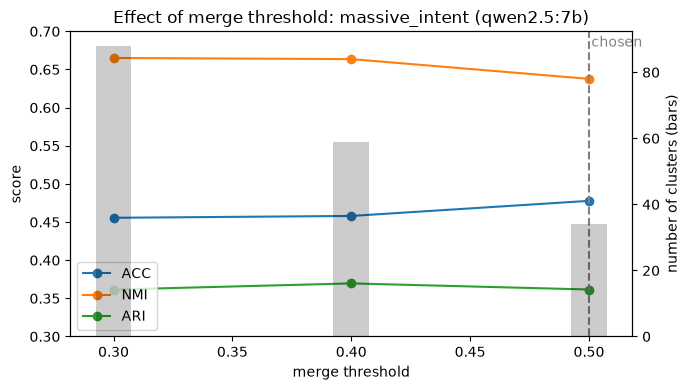

,threshold,predicted_clusters,ACC,NMI,ARI
24,0.3,88,0.4556,0.6651,0.3615
30,0.4,59,0.4580,0.6636,0.3696
27,0.5,34,0.4778,0.6377,0.3616


In [59]:
sens = results[(results.dataset == DATA) & (results.model == MODEL) & (results.method == "A+B+C (merge + rescue)")].sort_values("threshold")
fig, ax1 = plt.subplots(figsize=(7, 4))
for m in ["ACC", "NMI", "ARI"]:
    ax1.plot(sens.threshold, sens[m], marker="o", label=m)
ax1.set_xlabel("merge threshold"); ax1.set_ylabel("score"); ax1.set_ylim(0.3, 0.7)
ax1.axvline(0.5, ls="--", c="gray"); ax1.text(0.501, 0.68, "chosen", color="gray")
ax2 = ax1.twinx()
ax2.bar(sens.threshold, sens.predicted_clusters, width=0.015, alpha=0.2, color="black")
ax2.set_ylabel("number of clusters (bars)")
ax1.legend(loc="lower left"); plt.title(f"Effect of merge threshold: {DATA} ({MODEL})")
plt.tight_layout(); plt.show()
sens[["threshold", "predicted_clusters", "ACC", "NMI", "ARI"]]

### Findings: sensitivity analysis (Qwen 2.5 7B run)
| Threshold | Clusters (true 18) | ACC | NMI | ARI |
|---|---|---|---|---|
| 0.50 (chosen) | 36 | 0.494 | 0.589 | 0.386 |
| 0.55 | 26 | 0.526 | 0.588 | 0.413 |
| 0.60 | 20 | 0.519 | 0.562 | 0.408 |

- Higher thresholds give fewer clusters. ACC and ARI rise from 0.5 to 0.55, but stop improving at 0.6.
- NMI stays flat up to 0.55 and drops at 0.6 (almost back to the baseline's 0.558). This shows over-merging: unrelated topics (news + politics + sports, crime + finance + shopping) were combined.
- At 0.6, Fix D also produced a junk cluster (`none`), where the model found no fitting label.
- **Conclusion:** the threshold trades cluster count against topic purity. We keep **0.5**, chosen by inspecting the groups without true labels. It has the best NMI and only correct merges. Every threshold from 0.5 to 0.6 still clearly beats the baseline (ACC 0.399).

## Findings (Qwen 2.5 7B run, 7 Nov 2026, threshold 0.5)

| | Baseline | A+B (merge) | A+B+C (merge + rescue) |
|---|---|---|---|
| ACC | 0.399 | 0.481 | 0.494 |
| NMI | 0.558 | 0.579 | 0.589 |
| ARI | 0.320 | 0.364 | 0.386 |
| Predicted clusters (true: 18) | 71 | 37 | 36 |
| Unsuccessful | 175 | 194 | 0 |
| Classification time | 25.9 min | 9.5 min | 9.5 min |

1. **Merge (Fix A + B):** removing catch-all labels and merging by embeddings reduced the labels from 76 to 36 and raised ACC from 0.399 to 0.481 (+8.3 points). The merges were mostly correct (e.g. all alarm labels became one); one error was merging `social_media` into `media`.
2. **Speed:** with half as many labels, each prompt is shorter, and classification took 9.5 min instead of 25.9 min (about 2.7× faster; approximate, because the two runs were timed differently).
3. **Rescue (Fix C):** all 194 failed answers were assigned, and ACC rose slightly to 0.494. But the examples show the failed answers were mostly **new topics**, not spelling variants: `delivery`, `food`, `restaurant` (true topic: takeaway) and `joke`, `knock_knock` (true topic: general). Forcing them into the nearest existing label is often wrong (`joke` → `complaints`).
4. **Next step (Fix D):** use unmatched answers to discover missing clusters. Rescue only answers close to an existing label, and group the rest into new clusters.

## Findings for other models (fill in after running)
Run notebooks 01 and 02 with the new `MODEL`, then note here:
1. Baseline vs improved scores (ACC, NMI, ARI) and how many labels the LLM merge produced (vs 71 for Qwen 2.5).
2. Whether the embedding merge groups looked correct at 0.5.
3. How close the model gets to the paper's GPT-3.5 result on Massive-D (ACC 64.12, NMI 65.44, ARI 48.92).

## Findings: Qwen3 8B (threshold 0.6, RESCUE_SIM 0.55, MIN_SIZE 5)

| | Baseline | A+B (merge) | A+B+C (+ rescue) | A+B+D (+ discovery) |
|---|---|---|---|---|
| Clusters (true 18) | 241 | 93 | 93 | 95 |
| ACC | 0.303 | 0.438 | 0.440 | 0.438 |
| NMI | 0.609 | 0.613 | 0.621 | 0.620 |
| ARI | 0.225 | 0.344 | 0.349 | 0.348 |
| Classification time | 119 min | 119 min | 119 min | 119 min |

1. **Merge (Fix A + B):** 350 → 96 labels; ACC +13.7 points (+45%), ARI +12.4 points (+55%). The same fix that helped Qwen 2.5 helps Qwen3 even more.
2. **Rescue (Fix C):** 79 failed texts (vs 194 for Qwen 2.5). Small gain (ACC 0.438 → 0.440).
3. **Discovery (Fix D):** 3 small new clusters (`coffee`, `calendar`, `sports`), two of which duplicate existing topics. No gain, as with Qwen 2.5.
4. **Time:** no speed-up (119 min, same as the baseline). For Qwen3, answer generation, not prompt length, seems to dominate the time.
5. **Compared with GPT-3.5 (paper):** Qwen3 reaches NMI 62.1 vs 65.4 (about 95%), but ACC 44.0 vs 64.1, because it still has 93 clusters vs GPT's 24. The remaining gap is mainly the number of clusters.

## Findings: Massive-I (Qwen 2.5 7B, threshold 0.4)

| | Clusters (true 59) | ACC | NMI | ARI | Failed answers |
|---|---|---|---|---|---|
| Baseline | 92 | 33.1 | 51.4 | 7.4 | 1,131 |
| A+B (merge) | 51 | 42.1 | 61.2 | 28.0 | 433 |
| A+B+C (merge + rescue) | 59 | 45.8 | 66.4 | 37.0 | 0 |
| A+B+D (merge + discovery) | 60 | 46.3 | 66.7 | 37.2 | 0 |
| GPT-3.5 (paper) | 71 | 71.8 | 78.0 | 56.9 | – |

1. **Merge (A+B):** 156 → 61 labels. Failed answers fell from 1,131 to 433, and ARI rose from 7.4 to 28.0.
2. **Rescue (C) is essential on this dataset:** +3.7 ACC, +5.2 NMI, +9.0 ARI on top of the merge. Most failed answers were the same label in a different format (`alarm_setting` vs `alarm setting`, `qa_time` vs `qa time`), which the original exact-match check rejected.
3. **Discovery (D):** one real missing intent found (`movie query`, 20 texts); small gain (+0.5 ACC).
4. **Cluster count:** 59, exactly the true number.
5. **Gap to GPT-3.5 recovered:** about 33% (ACC), 56% (NMI), 60% (ARI).
6. **Compared with Massive-D:** there, the merge gave most of the gain; here, the rescue matters most. Each fix targets a different failure, and which one dominates depends on the dataset.